<a href="https://colab.research.google.com/github/naylaakas/PembelajaranMesin-2026/blob/main/JS06/datasetPBL/Praktikum2-FAISS.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install faiss-cpu
#!pip install faiss-gpu

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 19.5/19.5 MB 2.7 MB/s  0:00:07


In [4]:
import time
import faiss
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Load dan gabungkan dataset milikmu
df_cafes = pd.read_csv('cafes.csv')
df_reviews = pd.read_csv('reviews.csv')
df = pd.merge(df_reviews, df_cafes, on='cafe_id', how='left', suffixes=('_review', '_cafe'))

# Siapkan fitur 2D (latitude, longitude) dan 5D (5 fitur numerik) bertipe float32
X_2d_full = StandardScaler().fit_transform(
    df[['latitude', 'longitude']].fillna(0).values
).astype('float32')

X_5d_full = StandardScaler().fit_transform(
    df[['rating_review', 'rating_cafe', 'review_count', 'latitude', 'longitude']].fillna(0).values
).astype('float32')

print("Shape 2D Full:", X_2d_full.shape, "| dtype:", X_2d_full.dtype)
print("Shape 5D Full:", X_5d_full.shape, "| dtype:", X_5d_full.dtype)

Shape 2D Full: (2230, 2) | dtype: float32
Shape 5D Full: (2230, 5) | dtype: float32


Exact NN (Flat) indices : [[263 264 265]] | distances: [[0. 0. 0.]]
IVF+PQ indices          : [[263 264 265]] | distances: [[-0. -0. -0.]]
Waktu Exact             : 0.2327 ms
Waktu IVF+PQ            : 0.1938 ms


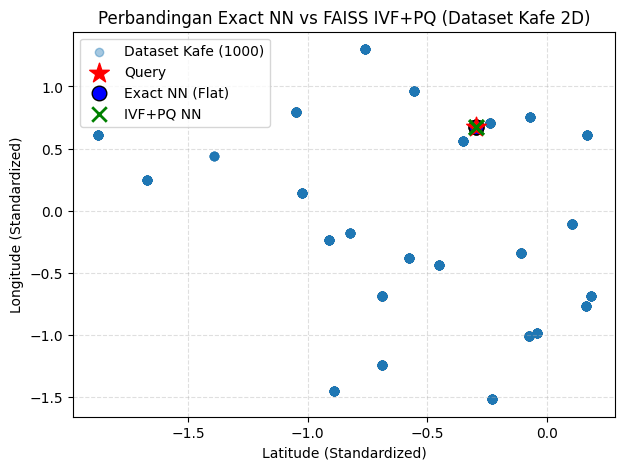

In [5]:
# 1. Ambil 1.000 data 2D dari dataset kafe & tentukan titik query
X = X_2d_full[:1000].copy()
query = X[500:501].copy()

# 2. Exact NN dengan IndexFlatL2 (brute force teroptimasi)
index_flat = faiss.IndexFlatL2(2)
index_flat.add(X)

start = time.time()
D_flat, I_flat = index_flat.search(query, 3)  # cari 3 tetangga terdekat
time_flat = (time.time() - start) * 1000      # konversi ke ms

# 3. IVF + PQ (Approximate Nearest Neighbor)
nlist = 10   # jumlah cluster
m = 2        # jumlah subvector (harus membagi habis dimensi d=2)
quantizer = faiss.IndexFlatL2(2)
index_ivfpq = faiss.IndexIVFPQ(quantizer, 2, nlist, m, 8)  # 8 bit per subvector

index_ivfpq.train(X)
index_ivfpq.add(X)
index_ivfpq.nprobe = 3

start = time.time()
D_ivfpq, I_ivfpq = index_ivfpq.search(query, 3)
time_ivfpq = (time.time() - start) * 1000     # konversi ke ms

# 4. Cetak hasil
print("Exact NN (Flat) indices :", I_flat, "| distances:", np.round(D_flat, 6))
print("IVF+PQ indices          :", I_ivfpq, "| distances:", np.round(D_ivfpq, 6))
print(f"Waktu Exact             : {time_flat:.4f} ms")
print(f"Waktu IVF+PQ            : {time_ivfpq:.4f} ms")

# 5. Visualisasi Scatter Plot
plt.figure(figsize=(7, 5))
plt.scatter(X[:, 0], X[:, 1], alpha=0.4, label="Dataset Kafe (1000)")
plt.scatter(query[:, 0], query[:, 1], c='red', marker='*', s=220, zorder=5, label="Query")
plt.scatter(X[I_flat[0], 0], X[I_flat[0], 1], c='blue', s=110, edgecolor='k', zorder=4, label="Exact NN (Flat)")
plt.scatter(X[I_ivfpq[0], 0], X[I_ivfpq[0], 1], c='green', marker='x', s=110, linewidths=2, zorder=6, label="IVF+PQ NN")

plt.legend()
plt.title("Perbandingan Exact NN vs FAISS IVF+PQ (Dataset Kafe 2D)")
plt.xlabel("Latitude (Standardized)")
plt.ylabel("Longitude (Standardized)")
plt.grid(True, linestyle='--', alpha=0.4)
plt.show()

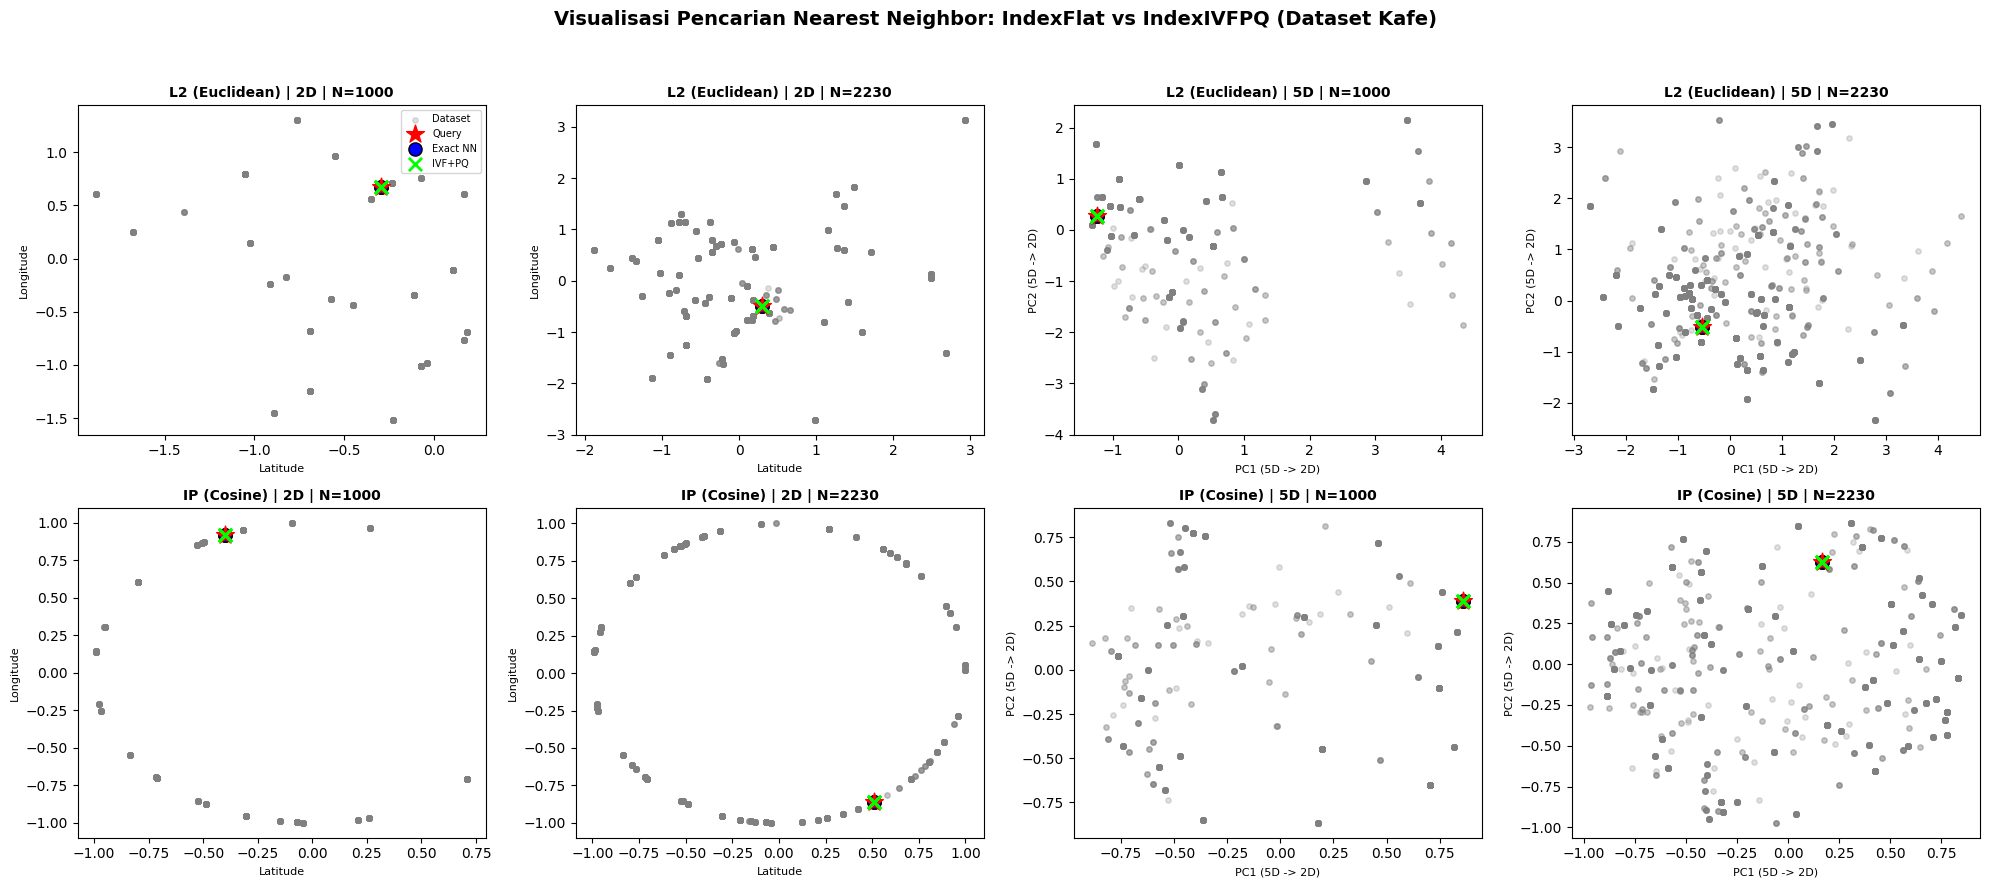

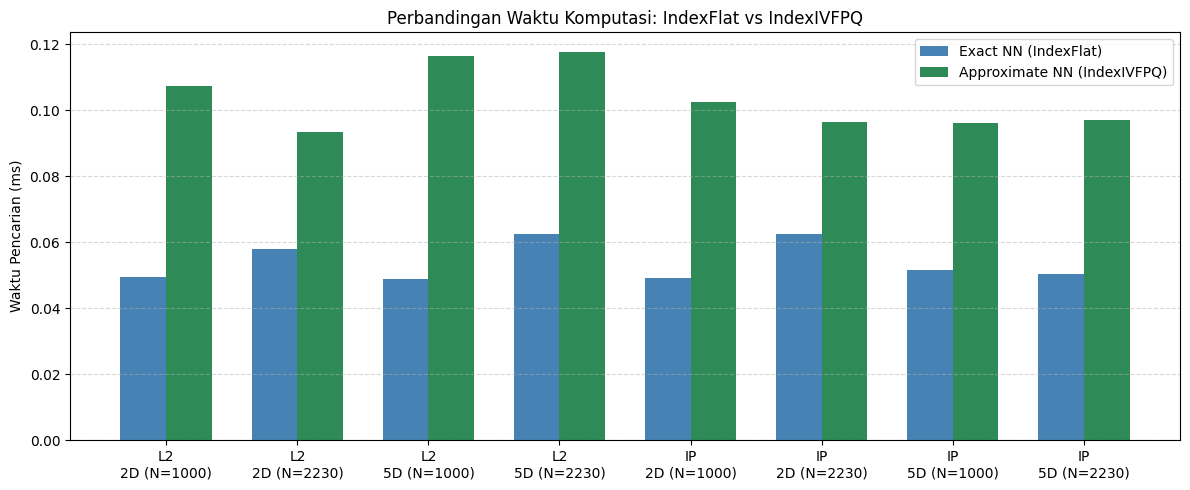


=== TABEL HASIL PERCOBAAN FAISS ===
Distance Metric Dimensi  Jumlah Data       Index Flat     Index IVF+PQ  Waktu Flat (ms)  Waktu IVF+PQ (ms)
 L2 (Euclidean)      2D         1000    [263 264 265]    [263 264 265]           0.0494             0.1073
 L2 (Euclidean)      2D         2230 [1112 1113 1114] [1112 1113 1114]           0.0579             0.0935
 L2 (Euclidean)      5D         1000    [264 265 266]    [264 265 266]           0.0489             0.1166
 L2 (Euclidean)      5D         2230 [1112 1113 1114] [1112 1113 1114]           0.0625             0.1178
    IP (Cosine)      2D         1000    [265 264 263]    [265 264 263]           0.0491             0.1025
    IP (Cosine)      2D         2230 [1114 1113 1112] [1114 1113 1112]           0.0625             0.0966
    IP (Cosine)      5D         1000    [266 265 264]    [266 265 264]           0.0517             0.0963
    IP (Cosine)      5D         2230 [1114 1113 1112] [1114 1113 1112]           0.0503             0.0970


In [6]:
daftar_eksperimen = [
    (X_2d_full[:1000], 'L2 (Euclidean)', '2D', 1000),
    (X_2d_full,        'L2 (Euclidean)', '2D', len(X_2d_full)),
    (X_5d_full[:1000], 'L2 (Euclidean)', '5D', 1000),
    (X_5d_full,        'L2 (Euclidean)', '5D', len(X_5d_full)),
    (X_2d_full[:1000], 'IP (Cosine)',    '2D', 1000),
    (X_2d_full,        'IP (Cosine)',    '2D', len(X_2d_full)),
    (X_5d_full[:1000], 'IP (Cosine)',    '5D', 1000),
    (X_5d_full,        'IP (Cosine)',    '5D', len(X_5d_full)),
]

fig, axes = plt.subplots(2, 4, figsize=(20, 9))
axes = axes.flatten()
hasil_tabel = []

for idx_plot, (X_raw, metric_name, dim_label, n_samples) in enumerate(daftar_eksperimen):
    ax = axes[idx_plot]
    X_work = X_raw.copy()
    d = X_work.shape[1]
    q = X_work[n_samples // 2 : n_samples // 2 + 1].copy()

    # Pilih Distance Metric: L2 (Euclidean) vs Inner Product (Cosine)
    if metric_name == 'IP (Cosine)':
        faiss.normalize_L2(X_work)
        faiss.normalize_L2(q)
        metric_type = faiss.METRIC_INNER_PRODUCT
        index_flat = faiss.IndexFlatIP(d)
        quantizer = faiss.IndexFlatIP(d)
    else:
        metric_type = faiss.METRIC_L2
        index_flat = faiss.IndexFlatL2(d)
        quantizer = faiss.IndexFlatL2(d)

    # Exact NN
    index_flat.add(X_work)
    t0 = time.time()
    _, I_flat = index_flat.search(q, 3)
    t_flat = (time.time() - t0) * 1000

    # IVF + PQ (m = d agar d habis dibagi m: m=2 untuk 2D, m=5 untuk 5D)
    index_ivfpq = faiss.IndexIVFPQ(quantizer, d, 10, d, 8, metric_type)
    index_ivfpq.train(X_work)
    index_ivfpq.add(X_work)
    index_ivfpq.nprobe = 3

    t0 = time.time()
    _, I_ivfpq = index_ivfpq.search(q, 3)
    t_ivfpq = (time.time() - t0) * 1000

    # Untuk 5D, proyeksikan ke 2D via PCA agar bisa digambar di scatter plot
    if d > 2:
        pca = PCA(n_components=2, random_state=42)
        X_plot = pca.fit_transform(X_work)
        q_plot = pca.transform(q)
        xlabel, ylabel = "PC1 (5D -> 2D)", "PC2 (5D -> 2D)"
    else:
        X_plot = X_work
        q_plot = q
        xlabel, ylabel = "Latitude", "Longitude"

    ax.scatter(X_plot[:, 0], X_plot[:, 1], alpha=0.25, s=15, color='gray', label="Dataset")
    ax.scatter(q_plot[:, 0], q_plot[:, 1], c='red', marker='*', s=180, zorder=5, label="Query")
    ax.scatter(X_plot[I_flat[0], 0], X_plot[I_flat[0], 1], c='blue', s=90, edgecolor='k', zorder=4, label="Exact NN")
    ax.scatter(X_plot[I_ivfpq[0], 0], X_plot[I_ivfpq[0], 1], c='lime', marker='x', s=90, linewidths=2, zorder=6, label="IVF+PQ")

    ax.set_title(f"{metric_name} | {dim_label} | N={n_samples}", fontsize=10, fontweight='bold')
    ax.set_xlabel(xlabel, fontsize=8)
    ax.set_ylabel(ylabel, fontsize=8)
    if idx_plot == 0:
        ax.legend(fontsize=7, loc='upper right')

    hasil_tabel.append({
        'Label': f"{metric_name.split()[0]}\n{dim_label} (N={n_samples})",
        'Distance Metric': metric_name,
        'Dimensi': dim_label,
        'Jumlah Data': n_samples,
        'Index Flat': str(I_flat[0]),
        'Index IVF+PQ': str(I_ivfpq[0]),
        'Waktu Flat (ms)': round(t_flat, 4),
        'Waktu IVF+PQ (ms)': round(t_ivfpq, 4)
    })

plt.suptitle("Visualisasi Pencarian Nearest Neighbor: IndexFlat vs IndexIVFPQ (Dataset Kafe)", fontsize=14, fontweight='bold')
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

# Plot Grafik Batang Perbandingan Waktu Komputasi
df_res = pd.DataFrame(hasil_tabel)
x_pos = np.arange(len(df_res))
width = 0.35

plt.figure(figsize=(12, 5))
plt.bar(x_pos - width/2, df_res['Waktu Flat (ms)'], width, label='Exact NN (IndexFlat)', color='steelblue')
plt.bar(x_pos + width/2, df_res['Waktu IVF+PQ (ms)'], width, label='Approximate NN (IndexIVFPQ)', color='seagreen')
plt.xticks(x_pos, df_res['Label'])
plt.ylabel('Waktu Pencarian (ms)')
plt.title('Perbandingan Waktu Komputasi: IndexFlat vs IndexIVFPQ')
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# Cetak Tabel Hasil
print("\n=== TABEL HASIL PERCOBAAN FAISS ===")
print(df_res[['Distance Metric', 'Dimensi', 'Jumlah Data', 'Index Flat', 'Index IVF+PQ', 'Waktu Flat (ms)', 'Waktu IVF+PQ (ms)']].to_string(index=False))